# 00. Data Preprocessing: The Builder Pipeline

**Project:** Synthetic Raman Spectra Generation for Glioma Detection  
**Role:** Builder (Raw Data $\rightarrow$ Processed HDF5)

This notebook executes the **one-time** preprocessing pipeline required to convert the raw 2D spectral scans into a machine-learning-ready dataset. Due to the computational cost of baseline correction algorithms, we separate this "Building" phase from the "Training" phase.

### 🎯 Objectives
1.  **Ingest:** Load raw `.npy` spectral cubes from the `data/raw/` directory.
2.  **Align:** Match spectra with their corresponding ground-truth tumor maps (`data/tumor_maps.npy`).
3.  **Clean:** Apply baseline correction and normalization to remove non-biological noise.
4.  **Structure:** Save the processed dataset into a highly optimized Hierarchical Data Format (HDF5) file for efficient I/O during training.

## 🔬 Preprocessing Methodology

Raman spectra are inherently noisy and contain background fluorescence that must be removed before training deep learning models. This pipeline applies the following transformations:

### 1. Baseline Correction: AirPLS
We utilize **Adaptive Iteratively Reweighted Penalized Least Squares (AirPLS)**. 
* **Purpose:** Removes the sloping background fluorescence (baseline drift) that varies between samples and spectrometers, while preserving the sharp Raman peaks that correspond to molecular vibrations.
* **Parameters:** `lambda=100`, `porder=1`.

### 2. Normalization: Min-Max
* **Purpose:** Scales the intensity of each spectrum to the range `[0, 1]`.
* **Why:** Neural networks (like VAEs and CNNs) converge significantly faster and more stably when input features are normalized.

### 3. Quality Control
* **Exclusion:** The sample `HF-1887_via-t_2_1.h5_3` is explicitly excluded from the dataset (as per previous literature, see APOLLO project) due to data quality issues.
* **Clipping:** Negative values resulting from baseline subtraction are clipped to 0.

In [1]:
# 00_Preprocessing.ipynb

import sys
import os
from pathlib import Path

# Add project root to path so we can import 'src'
# (Assuming notebook is in /notebooks and src is in /src)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.data.preprocessing import RamanPreprocessor
from src.data.loader import GliomaDataLoader
import numpy as np
import matplotlib.pyplot as plt

# --- Configuration ---
RAW_DATA_DIR = Path("../data/raw")
TUMOR_MAPS_PATH = Path("../data/tumor_maps.npy")
CALIB_PATH = Path("../data/RamanFreqTable.csv") 
OUTPUT_FILE = Path("../data/processed/glioma_dataset.h5")

# --- Initialize ---
preprocessor = RamanPreprocessor(
    raw_data_dir=RAW_DATA_DIR,
    tumor_maps_path=TUMOR_MAPS_PATH,
    calibration_path=CALIB_PATH, 
    output_file=OUTPUT_FILE,
    mask_strategy="bio_mask" # or "tumor_map"
)


print(f"Source: {preprocessor.raw_data_dir}")
print(f"Target: {preprocessor.output_file}")

2026-02-16 11:45:35.608268: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-02-16 11:45:42.489932: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


✅ Calibration Loaded. Range: 50.0 - 3399.8 cm⁻¹
Source: ../data/raw
Target: ../data/processed/glioma_dataset.h5


> ⚠️ **IMPORTANT USAGE NOTE**
>
> **Run this notebook only ONCE.**
>
> The AirPLS algorithm is computationally intensive. Processing ~300,000 spectra may take **1-2 hours** depending on your CPU. Once the `glioma_dataset.h5` file is generated, you do not need to run this notebook again unless the raw data changes.
>
> Future experiments (CVAE, SVM, etc.) will simply load the processed `.h5` file in seconds.

🔎 Current Strategy: 'bio_mask'
📂 Found 60 raw files. Searching for first valid tissue sample...

✅ SUCCESS: Found tissue in HF-448_V5B_1.h5_3.npy
   Cube Shape: (60, 60, 1738)
   Tissue Pixels: 3088


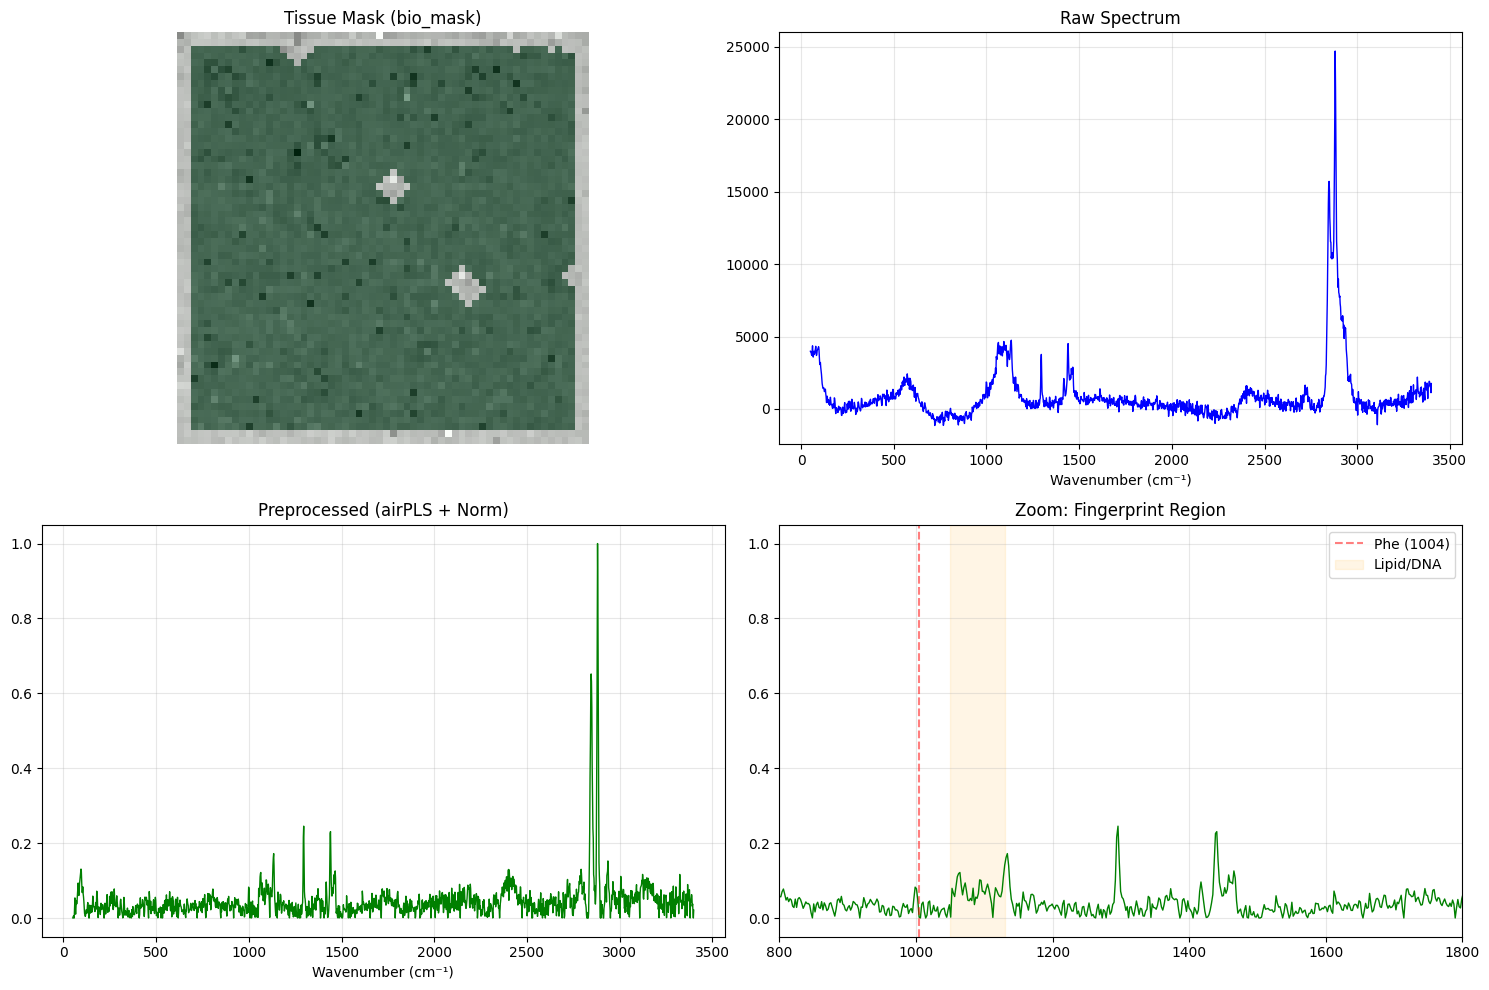

Stats:
Raw range: -1142.9 - 24715.0
Proc range: 0.000 - 1.000


In [2]:
# --- Step 1.5: Visual Proof-of-Concept ---
# Test preprocessing on a single real tissue spectrum based on selected strategy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import natsort
import os
import glob
import tqdm

# 1. Get list of files
raw_files = natsort.natsorted(list(Path(preprocessor.raw_data_dir).rglob("*.npy")))

print(f"🔎 Current Strategy: '{preprocessor.mask_strategy}'")
print(f"📂 Found {len(raw_files)} raw files. Searching for first valid tissue sample...")

# 2. Lazy Load & Check for Tissue
test_file = None
test_mask = None
raw_cube = None
tumor_maps_lookup = {}

# If strategy is tumor_map, load them once
if preprocessor.mask_strategy == "tumor_map":
    print(f"   Loading tumor maps from {preprocessor.tumor_maps_path}...")
    try:
        loaded_maps = np.load(preprocessor.tumor_maps_path, allow_pickle=True)
        if loaded_maps.ndim == 0: loaded_maps = loaded_maps.item()
        
        if isinstance(loaded_maps, dict) and 'data' in loaded_maps:
            tumor_maps_lookup = loaded_maps['data']
        elif isinstance(loaded_maps, dict):
             tumor_maps_lookup = loaded_maps
        else:
             print("⚠️ Warning: Tumor map structure ambiguous. Map lookup might fail.")
    except Exception as e:
        print(f"⚠️ Failed to load tumor maps: {e}")

# Search loop
for filepath in raw_files:
    # Skip excluded files
    if any(ex in str(filepath) for ex in preprocessor.IGNORE_SAMPLES):
        continue
        
    try:
        # Load raw data
        cube = np.load(str(filepath))
        filename = filepath.name
        mask = None
        
        # --- STRATEGY LOGIC ---
        if preprocessor.mask_strategy == "bio_mask":
            # Dynamic calculation using your new robust filter
            mask = preprocessor._create_bio_mask(cube)
            
        elif preprocessor.mask_strategy == "tumor_map":
            # Lookup logic
            key = filename
            if key not in tumor_maps_lookup: key = filename.replace('.npy', '')
            t_map = tumor_maps_lookup.get(key)
            if t_map is not None: mask = (t_map == 1)
        
        # Check yield
        if mask is not None and np.sum(mask) > 10: # Found a good sample!
            test_file = filepath
            test_mask = mask
            raw_cube = cube
            break
            
    except Exception as e:
        print(f"Skipping {filepath.name}: {e}")
        continue

# 3. Visualize
if test_file is None:
    print("❌ No valid tissue found in the scanned files.")
else:
    print(f"\n✅ SUCCESS: Found tissue in {test_file.name}")
    print(f"   Cube Shape: {raw_cube.shape}")
    print(f"   Tissue Pixels: {np.sum(test_mask)}")
    
    # Extract
    valid_spectra = raw_cube[test_mask]
    
    # Pick random spectrum
    idx = np.random.randint(0, valid_spectra.shape[0])
    raw_spec = valid_spectra[idx]
    
    # Preprocess
    proc_spec = preprocessor._preprocess_spectrum(raw_spec)
    
    # Plot
    wavenumbers = preprocessor.wavenumbers
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Mask Visualization
    ax_map = axes[0, 0]
    ax_map.imshow(np.mean(raw_cube, axis=2), cmap='gray')
    ax_map.imshow(test_mask, cmap='Greens', alpha=0.5)
    ax_map.set_title(f"Tissue Mask ({preprocessor.mask_strategy})")
    ax_map.axis('off')
    
    # Raw Spectrum
    ax_raw = axes[0, 1]
    ax_raw.plot(wavenumbers, raw_spec, 'b-', lw=1)
    ax_raw.set_title("Raw Spectrum")
    ax_raw.set_xlabel("Wavenumber (cm⁻¹)")
    ax_raw.grid(True, alpha=0.3)
    
    # Processed Spectrum
    ax_proc = axes[1, 0]
    ax_proc.plot(wavenumbers, proc_spec, 'g-', lw=1)
    ax_proc.set_title("Preprocessed (airPLS + Norm)")
    ax_proc.set_xlabel("Wavenumber (cm⁻¹)")
    ax_proc.grid(True, alpha=0.3)
    
    # Zoom in on Bio-Markers
    ax_zoom = axes[1, 1]
    ax_zoom.plot(wavenumbers, proc_spec, 'g-', lw=1)
    ax_zoom.set_title("Zoom: Fingerprint Region")
    ax_zoom.set_xlim(800, 1800) # Most relevant region
    ax_zoom.grid(True, alpha=0.3)
    
    # Highlight Key Markers
    ax_zoom.axvline(1004, color='r', linestyle='--', alpha=0.5, label='Phe (1004)')
    ax_zoom.axvspan(1050, 1130, color='orange', alpha=0.1, label='Lipid/DNA')
    ax_zoom.legend()
    
    plt.tight_layout()
    plt.show()
    
    print("Stats:")
    print(f"Raw range: {raw_spec.min():.1f} - {raw_spec.max():.1f}")
    print(f"Proc range: {proc_spec.min():.3f} - {proc_spec.max():.3f}")

In [3]:
# --- Configuration ---
RAW_DATA_DIR = Path("../data/raw")
CALIB_PATH = Path("../data/RamanFreqTable.csv")
OUTPUT_IMG_DIR = Path("../data/rgb_img_bio_markers")

# Create output directory
os.makedirs(OUTPUT_IMG_DIR, exist_ok=True)
print(f"📂 Output folder created: {OUTPUT_IMG_DIR}")

# --- 1. Load Calibration (Standardized Logic) ---
def load_wavenumbers(path, target_length=1738):
    df = pd.read_csv(path)
    # Assuming the file has 'idx,freq' or similar. We take the 2nd column.
    wavenumbers = df.iloc[:, 1].values
    
    # Extrapolate if length mismatch (standard fix for this dataset)
    if len(wavenumbers) < target_length:
        diff = np.mean(np.diff(wavenumbers[-10:]))
        padding = [wavenumbers[-1] + diff * i for i in range(1, target_length - len(wavenumbers) + 1)]
        wavenumbers = np.concatenate([wavenumbers, padding])
        
    return wavenumbers

try:
    wavenumbers = load_wavenumbers(CALIB_PATH)
    print(f"✅ Calibration loaded. Shape: {wavenumbers.shape}")
except Exception as e:
    print(f"❌ Error loading calibration: {e}")
    # Stop if no calibration, as indices will be wrong
    raise


# --- 2. Visualize Bio-Markers as False Color RGB ---
def raman_to_bio_rgb(hsi_cube, wavenumbers):
    """
    Converts a Raman Hyperspectral Cube to a 'False Color' RGB image 
    highlighting biological markers.
    
    Args:
        hsi_cube: (H, W, D) Raw or Preprocessed Data
        wavenumbers: (D,) Vector of cm^-1 values
    
    Returns:
        rgb_img: (H, W, 3) Normalized image for display
    """
    H, W, D = hsi_cube.shape
    
    # --- 1. Define Marker Indices ---
    # RED Channel: Phenylalanine (1004 cm^-1) - The "Sharp" Marker
    idx_phe_start = np.argmin(np.abs(wavenumbers - 990))
    idx_phe_end   = np.argmin(np.abs(wavenumbers - 1020))
    
    # GREEN Channel: C-H Stretch (2850-2950 cm^-1) - The "Massive" Marker (Lipids)
    idx_hwn_start = np.argmin(np.abs(wavenumbers - 2800))
    idx_hwn_end   = np.argmin(np.abs(wavenumbers - 3000))
    
    # BLUE Channel: CH2 Deformation (1440-1450 cm^-1) - General Organic
    idx_ch2_start = np.argmin(np.abs(wavenumbers - 1430))
    idx_ch2_end   = np.argmin(np.abs(wavenumbers - 1460))
    
    # --- 2. Extract Bands (Integration/Sum) ---
    # We sum the area under the peak (more robust than single pixel)
    R = np.sum(hsi_cube[:, :, idx_phe_start:idx_phe_end], axis=2)
    G = np.sum(hsi_cube[:, :, idx_hwn_start:idx_hwn_end], axis=2)
    B = np.sum(hsi_cube[:, :, idx_ch2_start:idx_ch2_end], axis=2)
    
    # --- 3. Normalize per Channel (Contrast Stretch) ---
    # This ensures weak signals don't disappear
    def norm(c):
        c = c - np.min(c)
        return c / (np.max(c) + 1e-8)
    
    R = norm(R)
    G = norm(G)
    B = norm(B)
    
    # --- 4. Stack ---
    rgb_img = np.stack([R, G, B], axis=-1)
    
    # Boost gamma for visibility (optional)
    rgb_img = np.power(rgb_img, 0.8) 
    
    return rgb_img

# --- 3. Processing Loop ---
raw_files = natsort.natsorted(list(RAW_DATA_DIR.rglob("*.npy")))
print(f"🔍 Found {len(raw_files)} scans. Generating images...")

for filepath in tqdm.tqdm(raw_files, desc="Saving Images"):
    filename = filepath.name
    if "via-t" in filename: continue # Skip known bad files

    try:
        # Load Data
        raw_cube = np.load(filepath)
        if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
             raw_cube = raw_cube.item().get('data', raw_cube)
        
        # Generate Image
        rgb_img = raman_to_bio_rgb(raw_cube, wavenumbers)
        
        # Save
        save_name = filename.replace('.npy', '.png')
        plt.imsave(OUTPUT_IMG_DIR / save_name, rgb_img)
        
    except Exception as e:
        print(f"⚠️ Failed {filename}: {e}")

print(f"✅ All images saved to {OUTPUT_IMG_DIR}")

📂 Output folder created: ../data/rgb_img_bio_markers
✅ Calibration loaded. Shape: (1738,)
🔍 Found 60 scans. Generating images...


Saving Images:   0%|          | 0/60 [00:00<?, ?it/s]

Saving Images: 100%|██████████| 60/60 [00:20<00:00,  2.88it/s]

✅ All images saved to ../data/rgb_img_bio_markers


In [4]:
# --- Pre-Calculation / Dry Run (Bio-Mask Strategy) ---
import numpy as np
import os
from tqdm import tqdm
from src.data.preprocessing import RamanPreprocessor

# Configuration for the Dry Run
STRATEGY = "bio_mask"
print(f"📊 Starting Census using strategy: '{STRATEGY}'...")

# Initialize a dummy processor to access the mask logic
# We only need it to load calibration and provide the _create_bio_mask method
temp_proc = RamanPreprocessor(
    raw_data_dir=RAW_DATA_DIR,
    output_file=OUTPUT_FILE,
    mask_strategy=STRATEGY,
    calibration_path=CALIB_PATH
)

# Find files (use pathlib for OS-agnostic paths)
raw_files = sorted([p for p in RAW_DATA_DIR.glob("LGm-*/*.npy")])
total_spectra = 0
files_with_tissue = 0

print(f"🔍 Scanning {len(raw_files)} raw files...")

for filepath in tqdm(raw_files, desc="Census"):
    filepath = Path(filepath)  # ensure Path object
    filename = filepath.name

    # Skip ignored files
    if any(ignored in filename for ignored in temp_proc.IGNORE_SAMPLES):
        continue

    try:
        # Load raw cube (pass str for numpy compatibility)
        raw_cube = np.load(str(filepath))
        if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
            raw_cube = raw_cube.item().get('data', raw_cube)

        # Calculate Mask using Physics
        mask = temp_proc._create_bio_mask(raw_cube)
        n_tissue = np.sum(mask)

        if n_tissue > 0:
            total_spectra += n_tissue
            files_with_tissue += 1

    except Exception as e:
        print(f"⚠️ Error reading {filename}: {e}")
        continue

print("-" * 30)
print(f"✅ Census Complete ({STRATEGY})")
print(f"   Files containing tissue: {files_with_tissue} / {len(raw_files)}")
print(f"   Total Expected Spectra: {total_spectra}")
print("-" * 30)

📊 Starting Census using strategy: 'bio_mask'...
✅ Calibration Loaded. Range: 50.0 - 3399.8 cm⁻¹
🔍 Scanning 60 raw files...


Census: 100%|██████████| 60/60 [00:18<00:00,  3.25it/s]

------------------------------
✅ Census Complete (bio_mask)
   Files containing tissue: 58 / 60
   Total Expected Spectra: 249783
------------------------------


In [5]:
# --- Bias Check ---
# Check which classes the rejected files belong to and analyze distribution
rejected_classes = {i: 0 for i in range(1, 7)}  # LGm-1 through LGm-6
accepted_classes = {i: 0 for i in range(1, 7)}
rejected_files = []

import re
print("🚫 Rejected Files Analysis:")

for filepath in raw_files:
    filename = os.path.basename(filepath)
    
    # Skip explicitly ignored files
    if any(ignored in filename for ignored in temp_proc.IGNORE_SAMPLES):
        continue
    
    # Extract class from path (LGm-X) — use pathlib for cross-platform
    class_dir = None
    p = Path(filepath)
    for part in p.parts:
        if part.lower().startswith('lgm-'):
            try:
                class_dir = int(part.split('-', 1)[1])
            except Exception:
                class_dir = None
            break

    # Fallback: try to infer from filename if directory wasn't informative
    if class_dir is None:
        m = re.search(r'LGm[-_ ]?(\d)', str(p), re.IGNORECASE)
        if m:
            class_dir = int(m.group(1))
        else:
            continue
    
    try:
        # Load raw cube
        raw_cube = np.load(str(filepath))
        if isinstance(raw_cube, np.ndarray) and raw_cube.dtype == 'O':
            raw_cube = raw_cube.item().get('data', raw_cube)
        
        # Calculate Mask using Physics
        mask = temp_proc._create_bio_mask(raw_cube)
        n_tissue = np.sum(mask)
        
        if n_tissue > 0:
            accepted_classes[class_dir] += n_tissue
        else:
            rejected_classes[class_dir] += 1
            rejected_files.append((filename, class_dir))
    
    except Exception as e:
        rejected_classes[class_dir] += 1
        rejected_files.append((filename, class_dir, str(e)))

# Print Analysis
print(f"\n📊 Class Distribution Analysis:")
print(f"{'Class':<10} {'Accepted Spectra':<20} {'Rejected Files':<20}")
print("-" * 50)

total_by_class = 0
for class_num in range(1, 7):
    accepted = accepted_classes[class_num]
    rejected = rejected_classes[class_num]
    total_by_class += accepted
    print(f"LGm-{class_num:<3} {accepted:<20} {rejected:<20}")

print("-" * 50)
print(f"✅ Accepted Spectra Count: {total_spectra}")
print(f"   (Sum across classes: {total_by_class})")
print(f"   Total Rejected Files: {sum(rejected_classes.values())}")

if rejected_files:
    print(f"\n⚠️ Sample of Rejected Files:")
    for item in rejected_files[:10]:  # Show first 10
        if len(item) == 3:
            print(f"   {item[0]} (LGm-{item[1]}): {item[2]}")
        else:
            print(f"   {item[0]} (LGm-{item[1]})")
    if len(rejected_files) > 10:
        print(f"   ... and {len(rejected_files) - 10} more")


🚫 Rejected Files Analysis:

📊 Class Distribution Analysis:
Class      Accepted Spectra     Rejected Files      
--------------------------------------------------
LGm-1   32683                1                   
LGm-2   62941                0                   
LGm-3   45475                0                   
LGm-4   42015                0                   
LGm-5   52275                0                   
LGm-6   14394                0                   
--------------------------------------------------
✅ Accepted Spectra Count: 249783
   (Sum across classes: 249783)
   Total Rejected Files: 1

⚠️ Sample of Rejected Files:
   HF-9999_Test_1.npy (LGm-1)


In [6]:
# --- Step 2: Run the Pipeline ---
# This will take time (approx 1-2 hours for 300k spectra due to airPLS)
# The progress bar will show the status.
preprocessor.run()

🔍 Found 60 scan files.


Processing: 100%|██████████| 60/60 [1:04:27<00:00, 64.46s/it]


## 📂 Output Data Structure

The pipeline generates a single file: `data/processed/glioma_dataset.h5`. This file acts as a structured database containing:

| Dataset Key | Shape | Dtype | Description |
| :--- | :--- | :--- | :--- |
| **`/spectra`** | `(N, Bands)` | `float32` | The cleaned, normalized 1D Raman spectra. |
| **`/y_class`** | `(N,)` | `int32` | The specific glioma sub-type (Classes 1-6). |
| **`/y_tumor`** | `(N,)` | `int32` | Binary label: `0` = Normal Tissue, `1` = Tumor. |
| **`/sample_ids`** | `(N,)` | `string` | **CRITICAL:** The unique ID of the tissue slice (e.g., `HF-448`). Used to ensure strict Train/Test separation. |
| **`/patient_ids`**| `(N,)` | `int32` | The ID of the patient. |

This structure supports **"Group-Aware Splitting"**: when we train models later, we can split data based on `/sample_ids` to ensure that pixels from the same tissue slice never leak between Training and Testing sets.

Loading data from ../data/processed/glioma_dataset.h5...


Data Loaded. Shape: (294710, 1738)
Unique Samples: 58
Total Spectra: 294710
Total Bands: 1738
Unique Samples: 58


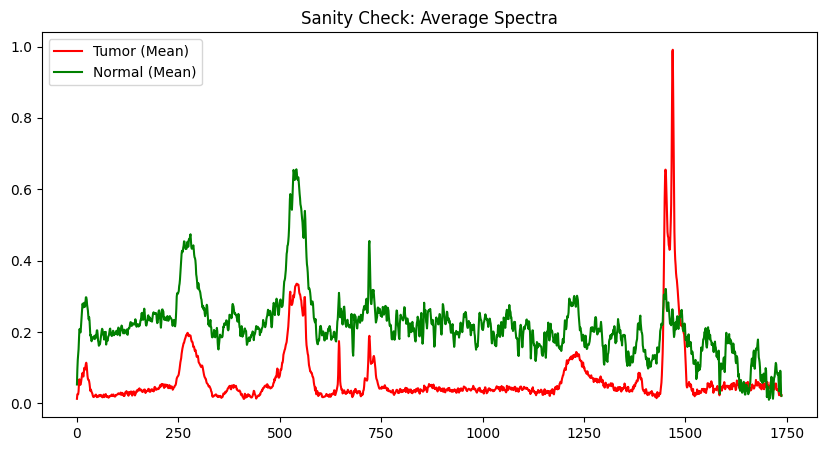

In [2]:
# --- Step 3: Verify the Output (Sanity Check) ---
# Load the file we just created to ensure it's readable
loader = GliomaDataLoader(OUTPUT_FILE, memory_mapped=True)

print(f"Total Spectra: {loader.X.shape[0]}")
print(f"Total Bands: {loader.X.shape[1]}")
print(f"Unique Samples: {len(np.unique(loader.groups))}")

# Visual Sanity Check
# Plot mean spectrum of Tumor vs Non-Tumor to see if biology is preserved
plt.figure(figsize=(10, 5))

# Indices for tumor vs normal
idx_tumor = np.where(loader.y_tumor[:] == 1)[0]
idx_normal = np.where(loader.y_tumor[:] == 0)[0]

# Compute mean (using a subset to save RAM if needed)
mean_tumor = np.mean(loader.X[idx_tumor[:5000]], axis=0)
mean_normal = np.mean(loader.X[idx_normal[:5000]], axis=0)

plt.plot(mean_tumor, color='red', label='Tumor (Mean)')
plt.plot(mean_normal, color='green', label='Normal (Mean)')
plt.title("Sanity Check: Average Spectra")
plt.legend()
plt.show()

In [3]:
from src.data.splitter import Splitter
# --- Create Data Splits ---
# 2. Generate and Save Splits
splitter = Splitter(data_path="../data/processed/glioma_dataset.h5", output_dir="../data/splits")
splitter.generate_manual_split() # Generates manual_splits.json

Saved manual splits to ../data/splits/manual_splits.json
